## Pandas analysis

This exercise consists in analyzing a dataset containg timing information from a series of Time-to-Digital-Converters (TDC) implemented in a couple of FPGAs. Each measurement (i.e. each row of the input file) consists of a flag that specifies the type of message ('HEAD', which in this case is always 1), two addresses of the TDC providing the signal ('FPGA' and 'TDC_CHANNEL'), and the timing information ('ORBIT_CNT', 'BX_COUNTER', and 'TDC_MEAS'). Each TDC count corresponds to 25/30 ns, whereas a unit of BX_COUNTER corresponds to 25 ns, and the ORBIT_CNT is increased every 'x' BX_COUNTER. This allows to store the time in a similar way to hours, minutes and seconds.

In [187]:
# If you didn't download it yet, please get the relevant file now!
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

import pandas as pd
import numpy as np

1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [188]:
N = int(70e3)
df = pd.read_csv("./data/data_000637.txt", nrows=N)
df

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25
...,...,...,...,...,...,...
69995,1,1,13,3869200863,809,19
69996,1,0,61,3869200863,810,26
69997,1,0,18,3869200863,812,6
69998,1,0,57,3869200863,813,18


In [189]:
bxPerOrbit = df.groupby("ORBIT_CNT").count()["BX_COUNTER"]
print(bxPerOrbit)
x = np.max(df["BX_COUNTER"])
print(f"'x' = {x}")

ORBIT_CNT
3869200167     43
3869200168     85
3869200169    127
3869200170     98
3869200171    109
             ... 
3869200859     93
3869200860     82
3869200861    130
3869200862     75
3869200863     43
Name: BX_COUNTER, Length: 697, dtype: int64
'x' = 3563


In [190]:
print("t0:")
orbit0 = df.at[0, "ORBIT_CNT"]
bx0 = df.at[0, "BX_COUNTER"]
tdc0 = df.at[0, "TDC_MEAS"]
t0 = 25e-9 * tdc0 + 30 * 25e-9 * bx0
print(orbit0, bx0, tdc0, " --> t0 =", t0)

print("max:")
orbit1 = df.at[df.shape[0]-1, "ORBIT_CNT"]
bx1 = df.at[df.shape[0]-1, "BX_COUNTER"]
tdc1 = df.at[df.shape[0]-1, "TDC_MEAS"]
t1 = 25e-9 * tdc1 + 30 * 25e-9 * bx1 + x * 30 * 25e-9 * (orbit1 - orbit0)
print(orbit1, bx1, tdc1, " --> t1 =", t1)

dt = t1 - t0
print("total elapsed time = ", dt)

t0:
3869200167 2374 26  --> t0 = 0.00178115
max:
3869200863 814 3  --> t1 = 1.8604965749999998
total elapsed time =  1.8587154249999998


In [191]:
df["abs_t"] = 25e-9 * df["TDC_MEAS"] + 30 * 25e-9 * df["BX_COUNTER"] + x * 30 * 25e-9 * (df["ORBIT_CNT"] - orbit0)
df

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,abs_t
0,1,0,123,3869200167,2374,26,0.001781
1,1,0,124,3869200167,2374,27,0.001781
2,1,0,63,3869200167,2553,28,0.001915
3,1,0,64,3869200167,2558,19,0.001919
4,1,0,64,3869200167,2760,25,0.002071
...,...,...,...,...,...,...,...
69995,1,1,13,3869200863,809,19,1.860493
69996,1,0,61,3869200863,810,26,1.860494
69997,1,0,18,3869200863,812,6,1.860495
69998,1,0,57,3869200863,813,18,1.860496


In [192]:
df["HEAD"] = np.random.randint(0, 2, df.shape[0])
df

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,abs_t
0,1,0,123,3869200167,2374,26,0.001781
1,0,0,124,3869200167,2374,27,0.001781
2,0,0,63,3869200167,2553,28,0.001915
3,1,0,64,3869200167,2558,19,0.001919
4,0,0,64,3869200167,2760,25,0.002071
...,...,...,...,...,...,...,...
69995,0,1,13,3869200863,809,19,1.860493
69996,0,0,61,3869200863,810,26,1.860494
69997,1,0,18,3869200863,812,6,1.860495
69998,1,0,57,3869200863,813,18,1.860496


In [196]:
filtDf = df[df["HEAD"] == 1]
filtDf

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,abs_t
0,1,0,123,3869200167,2374,26,0.001781
3,1,0,64,3869200167,2558,19,0.001919
7,1,0,139,3869200167,2776,0,0.002082
9,1,0,60,3869200167,2788,7,0.002091
10,1,1,7,3869200167,2785,4,0.002089
...,...,...,...,...,...,...,...
69991,1,1,50,3869200863,473,25,1.860241
69992,1,1,14,3869200863,506,18,1.860266
69993,1,0,124,3869200863,670,3,1.860389
69997,1,0,18,3869200863,812,6,1.860495


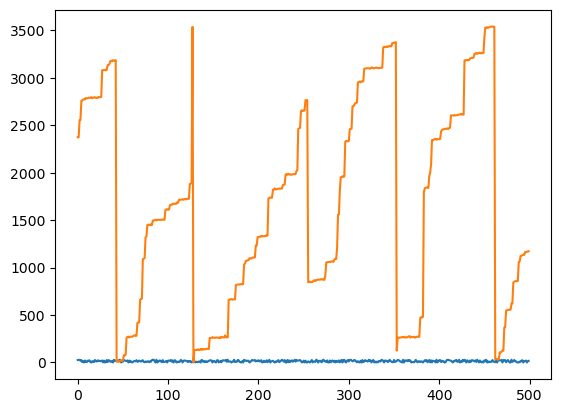

In [193]:
gByOrbit = df.head(500)["TDC_MEAS"].plot()
gByOrbit = df.head(500)["BX_COUNTER"].plot()
